# Portfolio selection with QAOA — Team **axiom**

**Qiskit Fall Fest 2026 · Track 2 (Quantum Optimization) · Level reached: Intermediate**

**Team:** Abhiram Arun N S V (`abhiramarun882@gmail.com`), Sree Sruthi Alur

This notebook reproduces the results reported in `README.md`, top to bottom, on **simulators only**
(no QPU and no IBM Runtime jobs were submitted). It rebuilds the exact problem, independently
re-checks the exact optima, and then loads the saved Phase 1–4 artifacts and prints / plots the
reported numbers.

**Headline result:** *no quantum advantage was demonstrated.* Classical greedy selection,
feasible-swap simulated annealing and relaxation + rounding all reach the exact optimum. The three
quantum methods match that solution quality but do not beat it.

Run time is about one minute on a laptop. Pinned versions are in `requirements.txt`.


## 0. Environment

Confirms the interpreter and package versions used throughout the project.

In [1]:
import os, sys, json, platform, importlib
from pathlib import Path

def find_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / "phase1_core.py").exists():
            return cand
    raise RuntimeError("project root (containing phase1_core.py) not found from %s" % p)

ROOT = find_root()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("project root :", ROOT)
print("python       :", platform.python_version(), "|", platform.platform())
for m in ["qiskit", "qiskit_aer", "qiskit_ibm_runtime", "qiskit_algorithms",
          "numpy", "scipy", "matplotlib"]:
    try:
        mod = importlib.import_module(m)
        print(f"{m:<20}= {getattr(mod, '__version__', '?')}")
    except Exception as exc:
        print(f"{m:<20}= unavailable ({exc})")

project root : D:\abhi\qff26-track2-axiom
python       : 3.13.14 | Windows-11-10.0.26300-SP0


qiskit              = 2.5.2
qiskit_aer          = 0.17.2


qiskit_ibm_runtime  = 0.50.0


qiskit_algorithms   = 0.4.0
numpy               = 2.5.4
scipy               = 1.18.1
matplotlib          = 3.11.2


## 1. Problem formulation

An investor must buy **exactly $K$ of $n$** assets, maximising return and minimising risk. With
$x_i = 1$ meaning "buy asset $i$":

$$C(x) = q\, x^{\top} \Sigma\, x \;-\; \mu^{\top} x \;+\; \lambda \Big( \sum_i x_i - K \Big)^2,
\qquad x \in \{0,1\}^n, \qquad \mathcal{F} = \Big\{ x : \sum_i x_i = K \Big\}.$$

Encoding conventions (fixed in Phase 1 and used everywhere):

- asset $i \leftrightarrow$ qubit $i$; state index $s = \sum_i x_i 2^i$ (qubit 0 is the LSB);
- the objective is mapped to a Pauli operator with $x_i = (I - Z_i)/2$.

The instance is the deterministic synthetic one from the challenge (seed `2026`, `q = 0.5`):
Beginner $n=6, K=3$ (20 feasible portfolios) and Intermediate $n=12, K=6$ (924 feasible).

In [2]:
import numpy as np
import phase1_core as core

BEGINNER = core.generate_instance(6, 3, q=0.5, seed=2026)
INTERMEDIATE = core.generate_instance(12, 6, q=0.5, seed=2026)

for name, inst in [("Beginner     n=6,K=3", BEGINNER),
                   ("Intermediate n=12,K=6", INTERMEDIATE)]:
    b = core.exact_benchmark(inst.n, inst.K, inst.mu, inst.Sigma, inst.q)
    print(f"{name}: feasible={b['feasible_count']}  "
          f"optimum={b['optimal_unpenalized_cost']:.12f}  "
          f"assets={b['optimal_asset_indices']}  "
          f"independent_agreement={b['independent_agreement']}")

Beginner     n=6,K=3: feasible=20  optimum=-0.503014690265  assets=[1, 2, 5]  independent_agreement=True
Intermediate n=12,K=6: feasible=924  optimum=-1.066392092347  assets=[1, 5, 6, 8, 10, 11]  independent_agreement=True


In [3]:
# Operator check: the cost-operator diagonal must equal the direct objective.
for name, inst in [("Beginner", BEGINNER), ("Intermediate", INTERMEDIATE)]:
    op, c_I, h, J = core.qubo_to_pauli(inst.mu, inst.Sigma, inst.q, inst.K, 1.0)
    diag = core.operator_diagonal(op)
    direct = np.array([core.cost_penalized(core.index_to_assets(s, inst.n), inst.mu,
                                           inst.Sigma, inst.K, 1.0, inst.q)
                       for s in range(2 ** inst.n)])
    print(f"{name}: max|Pauli diagonal - direct cost| = {np.max(np.abs(diag - direct)):.3e}")

Beginner: max|Pauli diagonal - direct cost| = 2.665e-15


Intermediate: max|Pauli diagonal - direct cost| = 1.776e-14


## 2. Beginner baseline (Phase 2)

Mandatory Beginner level: standard transverse-field QAOA, cost Hamiltonian $H_C(\lambda)$,
mixer $H_M = \sum_i X_i$, initial state $|+\rangle^{\otimes n}$. The exact penalty threshold
$\lambda^\*$ is the smallest penalty that makes the feasible optimum a global minimiser of the
penalised cost; it is derived by exhaustive enumeration (never from QAOA samples).

In [4]:
p2v = json.load(open("outputs/phase2/validation_report.json", encoding="utf-8"))
p2s = json.load(open("outputs/phase2/experiment_summary.json", encoding="utf-8"))

print("Phase 2 tests recorded :", p2v["tests"])
print("Beginner penalty threshold lambda* =", p2v["exact_penalty_analysis"]["penalty_threshold"])
print("Exact reference        :", p2s["exact_reference"])

bd = p2s["best_by_criterion"]["best_depth"]
exm = bd["sampling"]["exact_statevector_metrics"]
print(f"Best depth (lowest <H_C>) : p={bd['p']}  <H_C>={bd['best_energy']:.6f}  "
      f"feasibility_exact={exm['feasibility_rate']:.4f}  P(opt)_exact={exm['optimal_solution_probability']:.4f}")
rec = p2s["best_by_criterion"]["recommended_penalty"]
print(f"Recommended penalty       : lambda={rec['selected']['lambda']} at p={rec['selected']['p']} "
      "(smallest tested lambda >= threshold)")

Phase 2 tests recorded : {'tests_run': 82, 'passed': 82, 'failed': 0, 'errors': 0, 'skipped': 0}
Beginner penalty threshold lambda* = 0.10966122612466722
Exact reference        : {'C_best': -0.5030146902647753, 'C_worst': -0.22197117201541114, 'optimal_asset_indices': [1, 2, 5], 'optimal_assignment': [0, 1, 1, 0, 0, 1], 'feasible_count': 20, 'num_optimal_ties': 1, 'expected_optimum': -0.5030146902647753, 'optimum_match': True}
Best depth (lowest <H_C>) : p=4  <H_C>=-0.352906  feasibility_exact=0.9852  P(opt)_exact=0.0477
Recommended penalty       : lambda=0.25 at p=2 (smallest tested lambda >= threshold)


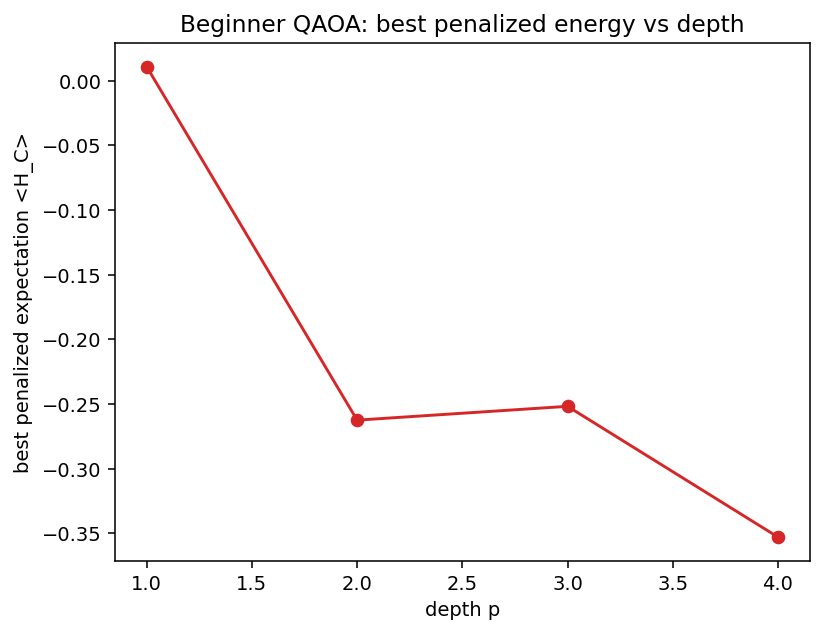

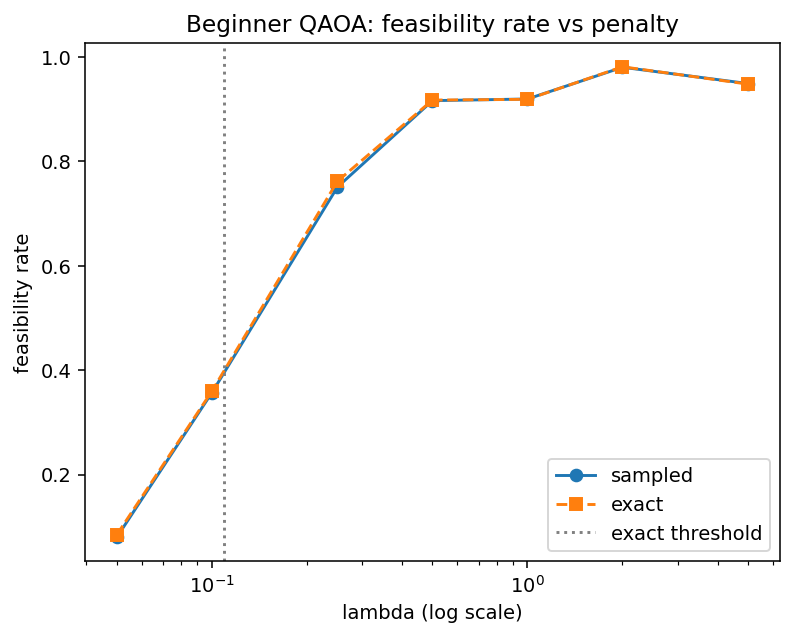

In [5]:
from IPython.display import Image, display
for fig in ["outputs/phase2/figures/depth_energy_vs_p.png",
            "outputs/phase2/figures/penalty_feasibility_vs_lambda.png"]:
    display(Image(filename=fig))

## 3. Intermediate: three quantum methods vs classical baselines (Phase 3)

Instance $n=12, K=6$, seed `2026`, `q=0.5`.

| | Method | Mixer | Initial state | Penalty |
|---|---|---|---|---|
| **A** | Constraint-preserving XY-QAOA | ring XY mixer | uniform weight-$K$ state | none (mixer preserves weight) |
| **B** | Warm-start QAOA | $\sum_i X_i$ | product $R_y$ state | $\lambda = 1$ |
| **C** | Penalised standard QAOA | $\sum_i X_i$ | $|+\rangle^{\otimes n}$ | $\lambda = 1$ |

Classical baselines: greedy forward selection, feasible-swap simulated annealing, and continuous
relaxation + rounding. All numbers below are read verbatim from the saved Phase 3 artifacts.

In [6]:
p3 = json.load(open("outputs/phase3/comparison_summary.json", encoding="utf-8"))
t3 = json.load(open("outputs/phase3/intermediate_penalty_threshold.json", encoding="utf-8"))

er = p3["exact_reference"]
print("Exact reference: C_best=%.12f  feasible=%d  optimal assets=%s"
      % (er["C_best"], er["feasible_count"], er["optimal_asset_indices"]))

for label, key in [("Method A (XY-QAOA)", "A_xy_qaoa"),
                   ("Method B (warm start)", "B_warm_start"),
                   ("Method C (penalised)", "C_penalty_qaoa")]:
    print(f"\n{label}:")
    for r in p3["quantum"][key]["records"]:
        print(f"  p={r['p']}: best_feasible_exact={r['best_feasible_exact']:.6f}  "
              f"feasibility_exact={r['feasibility_rate_exact']:.3f}  "
              f"P(opt)_exact={r['optimal_prob_exact']:.6f}  "
              f"score_exact={r['score_exact']:.4f}  starts={r['num_successful']}/{r['num_starts']}")

g = p3["classical"]["greedy"]
s = p3["classical"]["simulated_annealing"]
print(f"\nClassical greedy : C0={g['objective']:.12f}  assets={g['asset_indices']}  gap={g['gap_to_optimum']}  wall={g['runtime_s']:.4f}s")
print(f"Classical SA     : C0={s['best_cost']:.12f}  assets={s['best_asset_indices']}  gap={s['gap_to_optimum']}  wall={s['total_runtime_s']:.3f}s")
print(f"Relaxation+round : best_objective={p3['continuous_relaxation']['best_objective']:.6f}  gap_to_optimum={p3['continuous_relaxation']['gap_to_optimum']:.6f}")

print("\nIntermediate penalty threshold lambda* =", t3["lambda_star"])
print("Verdict:", p3["verdict"]["note"])

Exact reference: C_best=-1.066392092347  feasible=924  optimal assets=[1, 5, 6, 8, 10, 11]

Method A (XY-QAOA):
  p=1: best_feasible_exact=-1.066392  feasibility_exact=1.000  P(opt)_exact=0.000473  score_exact=0.5197  starts=3/5
  p=2: best_feasible_exact=-1.066392  feasibility_exact=1.000  P(opt)_exact=0.000591  score_exact=0.5329  starts=0/6
  p=3: best_feasible_exact=-1.066392  feasibility_exact=1.000  P(opt)_exact=0.006636  score_exact=0.5666  starts=0/6

Method B (warm start):
  p=1: best_feasible_exact=-1.066392  feasibility_exact=0.422  P(opt)_exact=0.103696  score_exact=0.9438  starts=5/5
  p=2: best_feasible_exact=-1.066392  feasibility_exact=0.536  P(opt)_exact=0.149355  score_exact=0.9483  starts=5/5
  p=3: best_feasible_exact=-1.066392  feasibility_exact=0.691  P(opt)_exact=0.160867  score_exact=0.9420  starts=3/5

Method C (penalised):
  p=1: best_feasible_exact=-1.066392  feasibility_exact=0.211  P(opt)_exact=0.000223  score_exact=0.4893  starts=5/5
  p=2: best_feasible_e

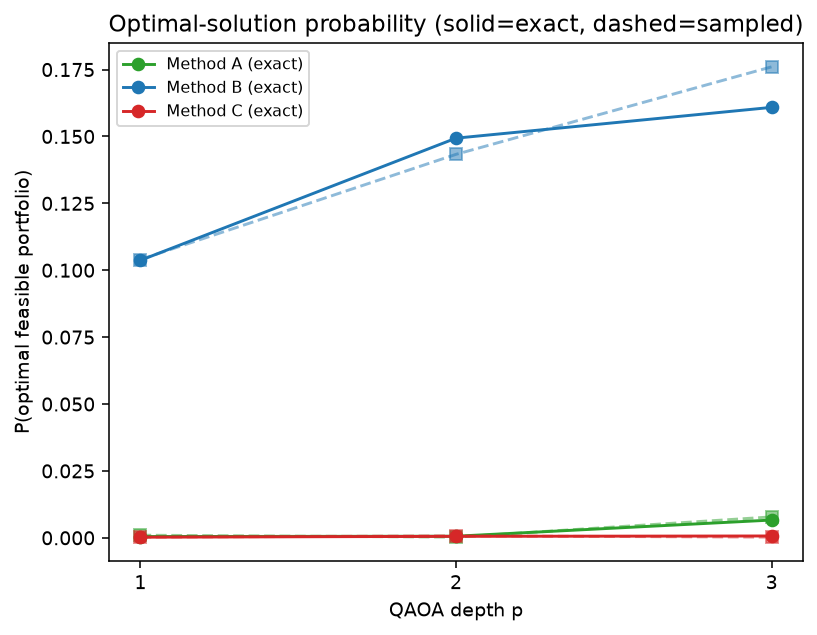

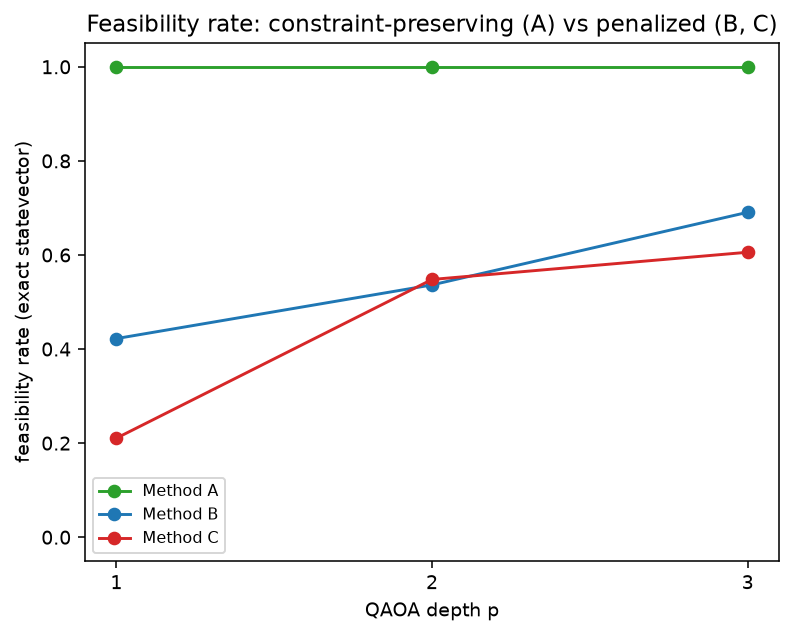

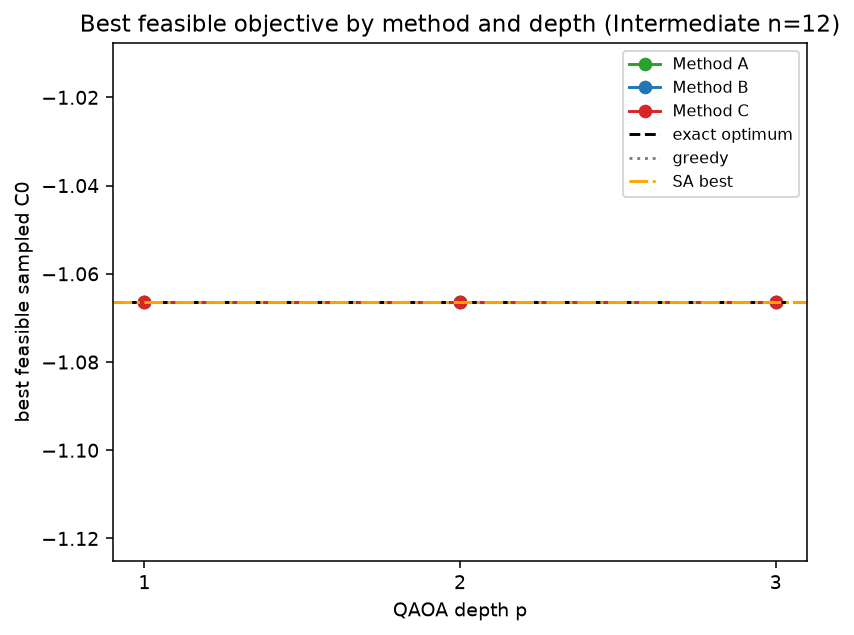

In [7]:
for fig in ["outputs/phase3/figures/optimal_prob_vs_depth.png",
            "outputs/phase3/figures/feasibility_vs_depth.png",
            "outputs/phase3/figures/best_feasible_vs_method_depth.png"]:
    display(Image(filename=fig))

## 4. Hardware awareness and noisy simulation (Phase 4)

The selected Method A circuit ($p=3$) is reconstructed as a **gate-based** circuit, transpiled for
the IBM `FakeBrisbane` device model, and compared a noiseless statevector reference against a
`FakeBrisbane`-noisy `Aer` run of the *same* circuit. Everything is simulator only.

Two separate effects are reported and never mixed:

1. **Trotterization / implementation gap** — the gate-based circuit must decompose the
   non-commuting XY-ring mixer into a first-order Trotter product, while Phase 3 optimised the
   exact matrix exponential. This is *not* hardware noise.
2. **Hardware noise** — `FakeBrisbane`-derived noise on the transpiled circuit.

In [8]:
cr = json.load(open("outputs/phase4/circuit_resources.json", encoding="utf-8"))
cmp_ = json.load(open("outputs/phase4/comparison_summary.json", encoding="utf-8"))
ideal = json.load(open("outputs/phase4/ideal_results.json", encoding="utf-8"))
noisy = json.load(open("outputs/phase4/noisy_results.json", encoding="utf-8"))

print("Backend:", cr["backend"]["name"], "| qubits:", cr["backend"]["num_qubits"],
      "| coupling edges:", cr["backend"]["num_coupling_edges"])
print("Selected Method A p =", cr["selection"]["p"],
      "| artifact sha256 =", cr["selection"]["artifact_sha256"][:12], "...")

print("\nResources (logical -> transpiled):")
for label, key in [("logical opaque", "logical_opaque"),
                   ("logical decomposed", "logical_decomposed"),
                   ("state prep transpiled", "state_preparation_transpiled"),
                   ("transpiled subgraph", "transpiled_subgraph"),
                   ("transpiled full device", "transpiled_full_device")]:
    r = cr[key]
    print(f"  {label:<24} depth={r['depth']:>7}  size={r['size']:>7}  2q={r['two_qubit_gate_count']:>6}")
print("  routing required fraction:", round(cr["routing_analysis"]["routing_required_fraction"], 4))
print("  state-prep share of transpiled depth:", round(cr["state_preparation_contribution"]["share_of_transpiled_depth"], 4))

ie = cmp_["metrics_ideal_exact"]; in_ = cmp_["metrics_noisy_sampled"]
print("\nIdeal (circuit statevector, exact):")
print(f"  feasibility={ie['feasibility_rate']:.6f}  P(opt)={ie['optimal_solution_probability']:.7f}  "
      f"best feasible C0={ie['best_feasible_unpenalized_cost']:.6f}  mean C0|feas={ie['mean_c0_conditioned_on_feasible']:.6f}")
print(f"Noisy (FakeBrisbane, {noisy['raw']['shots']} shots, {noisy['elapsed_s']:.1f}s):")
print(f"  feasibility={in_['feasibility_rate']:.6f}  P(opt)={in_['optimal_solution_probability']:.7f}  "
      f"best feasible C0={in_['best_feasible_unpenalized_cost']:.6f}  mean C0|feas={in_['mean_c0_conditioned_on_feasible']:.6f}")
print("  TV(exact ideal, noisy) =", round(cmp_["total_variation_exact_vs_noisy"], 4),
      "| TV(equal-shot sampled) =", round(cmp_["total_variation_sampled_vs_sampled"], 4),
      "| feasibility drop =", round(cmp_["feasibility_rate_drop"], 4))

t = ideal["trotterization_gap"]
print("\nTrotterization / implementation gap (NOT hardware noise):")
print(f"  TV(circuit, exact subspace)={t['total_variation']:.4f}  max|dP|={t['max_abs_probability_difference']:.5f}  "
      f"fidelity(feasible subspace)={t['fidelity_on_feasible_subspace']:.4f}")
print(f"  P(opt): circuit {t['optimal_probability_circuit']:.7f} vs exact subspace {t['optimal_probability_subspace_exact']:.7f}")

Backend: fake_brisbane | qubits: 127 | coupling edges: 144
Selected Method A p = 3 | artifact sha256 = 33b0b95ff5b3 ...

Resources (logical -> transpiled):
  logical opaque           depth=      7  size=      7  2q=     0
  logical decomposed       depth=   8782  size=   9600  2q=  4623
  state prep transpiled    depth=  33392  size=  67719  2q=  9429
  transpiled subgraph      depth=  36008  size=  76430  2q= 10554
  transpiled full device   depth=  34092  size=  63925  2q=  8813
  routing required fraction: 0.5144
  state-prep share of transpiled depth: 0.9273

Ideal (circuit statevector, exact):
  feasibility=1.000000  P(opt)=0.0021148  best feasible C0=-1.066392  mean C0|feas=-0.658622
Noisy (FakeBrisbane, 1024 shots, 549.7s):
  feasibility=0.207031  P(opt)=0.0000000  best feasible C0=-1.026446  mean C0|feas=-0.648193
  TV(exact ideal, noisy) = 0.8936 | TV(equal-shot sampled) = 0.9072 | feasibility drop = 0.793

Trotterization / implementation gap (NOT hardware noise):
  TV(circuit

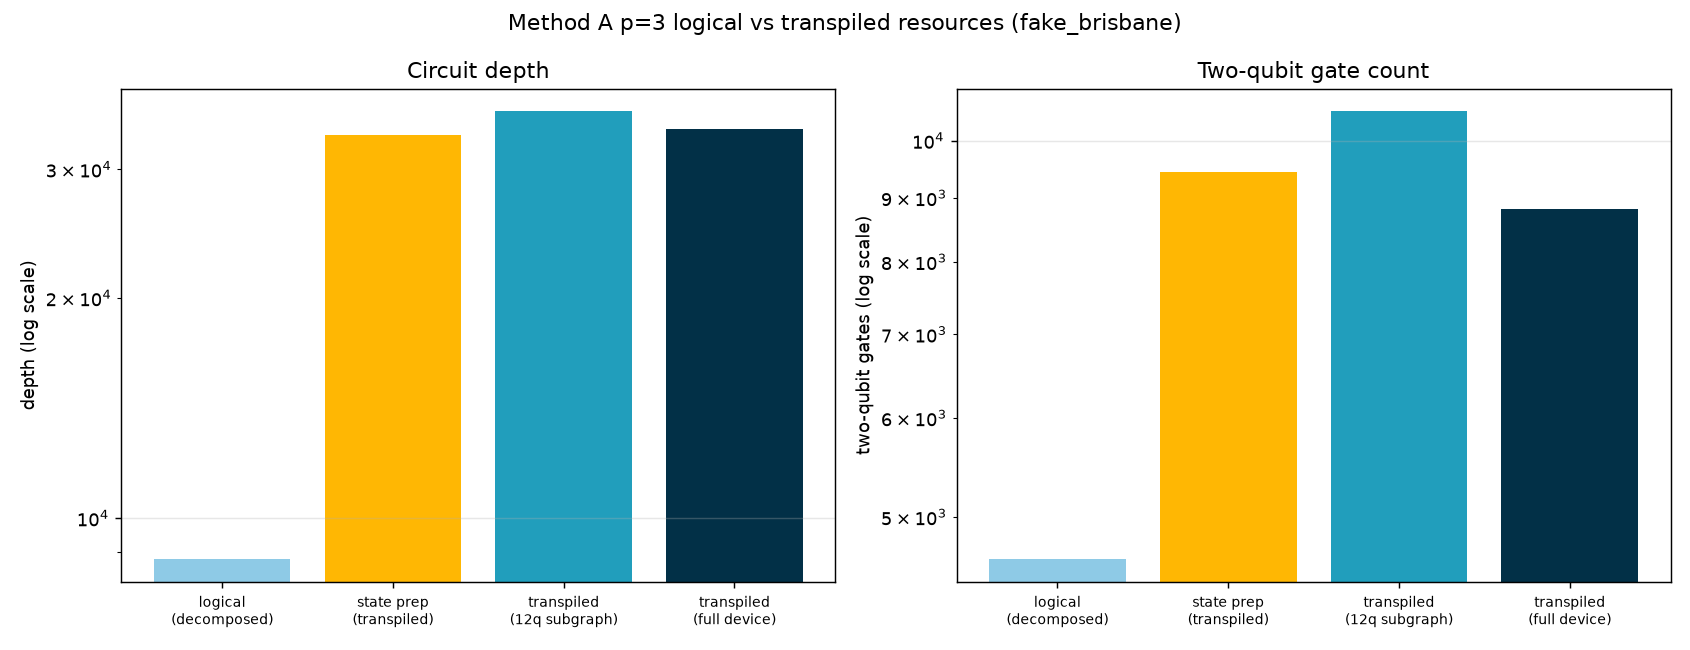

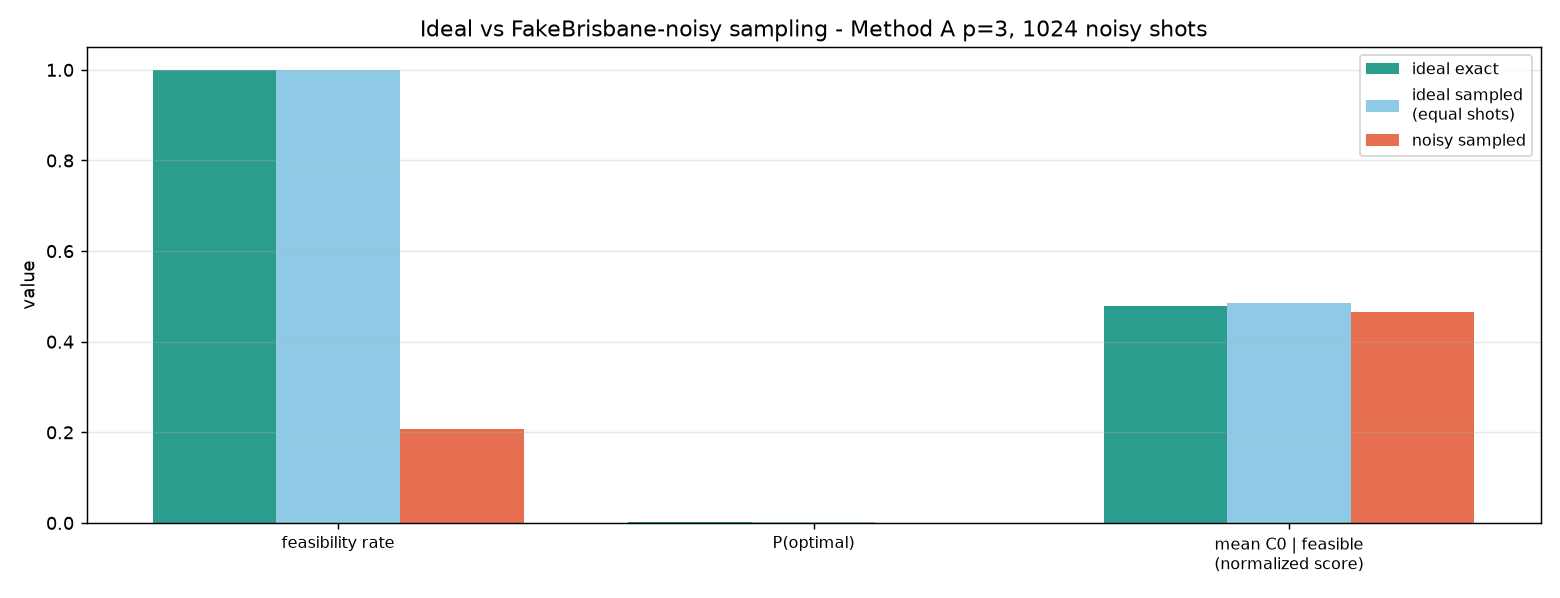

In [9]:
for fig in ["outputs/phase4/figures/logical_vs_transpiled_resources.png",
            "outputs/phase4/figures/ideal_vs_noisy_metrics.png"]:
    display(Image(filename=fig))

## 5. Conclusions and limitations

- **No quantum advantage.** Classical greedy and feasible-swap SA both reach the exact optimum
  `-1.0663920923466492` with zero gap in under 2 s, as does relaxation + rounding. Methods A, B and C
  match that solution quality but do not beat it; they differ in probability mass
  (B `0.16`, A `0.0066`, C `0.0007`) and runtime.
- **Constraint handling matters.** Method A (XY mixer) keeps every sample feasible at the cost of
  depth; Methods B and C buy speed/shallowness with infeasible mass.
- **Gate-based circuits pay a Trotterization cost.** The hardware-realizable Method A circuit has a
  much lower P(opt) than the exact operator-level value — an implementation effect, not noise.
- **Noise dominates at this depth.** On `FakeBrisbane` the 36008-deep, 10554-ECR circuit loses the
  signal: feasibility drops from 1.0 to 0.207 and the optimum is never sampled.
- **Simulator-only.** `FakeBrisbane` is a device *model*, not real hardware.


In [10]:
# Reproducibility: run a small slice of the unit-test suite from a fresh kernel,
# then print the full-suite command. The full 127-test suite is run separately (see README).
import unittest
subset = unittest.TestLoader().loadTestsFromNames(
    ["tests.test_bit_ordering", "tests.test_exact_benchmark"])
res = unittest.TextTestRunner(verbosity=0).run(subset)
print("notebook smoke tests:", "OK" if res.wasSuccessful() else "FAILED",
      f"({res.testsRun} tests, failures={len(res.failures)}, errors={len(res.errors)})")
print()
print("Full suite (from the project root):")
print("  .venv\\Scripts\\python.exe -m unittest discover -s tests -t .")
p4v = json.load(open("outputs/phase4/validation_report.json", encoding="utf-8"))
detail = next(c["detail"] for c in p4v["checks"] if c["check"] == "full test suite passed")
print("Recorded at Phase 4:", detail)

----------------------------------------------------------------------
Ran 13 tests in 0.103s

OK


notebook smoke tests: OK (13 tests, failures=0, errors=0)

Full suite (from the project root):
  .venv\Scripts\python.exe -m unittest discover -s tests -t .
Recorded at Phase 4: exit_code=0 tail=['  self._set_intXint(row, col, x.flat[0])', '..........................................', '----------------------------------------------------------------------', 'Ran 127 tests in 75.133s', '', 'OK']


## Credits and licences

- The Track 2 challenge and tutorial this work is built on are adapted from the **BasQ Qiskit Fall
  Fest** hackathon: tutorials by **Benjamin Tirado**; challenge prompt by Angel Rodriguez, Benjamin
  Tirado and Miguel Angel Jimenez. Text under CC BY 4.0, code under Apache 2.0.
  Citation: *B. Tirado, Combinatorial Optimization with QAOA: Max-Cut, tutorial notebook, BasQ
  Qiskit Fall Fest, 2026.*
- All model, circuit, simulation, analysis and text in this repository were written by Team axiom.
- **AI tools used:** an AI coding assistant (opencode) was used to draft and debug the Python
  modules, tests and this notebook. All reported numbers are produced by executing the code in this
  repository; no results were fabricated.
